<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/NN_EntanglementAdversarial_Hou2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FGSM and DeepFool adversarial attacks on a neural entanglement classifier for quantum states (Hou, 2023) step by step

This notebook re-implements, runs and checks the numerical experiment of

> Xiaokai Hou, "Adversarial Attack Generation in Quantum Data Classification",
> 2023 4th International Conference on Computer Science and Management Technology (ICCSMT 2023), October 13-15, 2023, Xi'an, China, ACM,
> pp. 548-551. DOI 10.1145/3644523.3644623.

**What the notebook does.** The paper asks whether two classical adversarial attacks, the *fast gradient sign method* (FGSM) and
*DeepFool*, also work on **quantum data**. The quantum data are random two-qubit states. Each state is turned into a classical 15-number vector
by measuring it against the 15 Gell-Mann matrices, and a classical neural network learns to say "entangled" or "separable" (the label comes from the
exact positive-partial-transpose test). The attacks then perturb the 15 numbers, and the paper reports how far the network's accuracy falls and how far
the perturbed vectors are (trace distance, fidelity) from the original states once they are turned back into density matrices.
Here we (i) generate the states from the paper's recipe (this is physics, not a downloaded file), (ii) train the paper's 15-H-1 network with plain
SGD in numpy, (iii) implement FGSM and DeepFool with exact gradients, (iv) rebuild Table 1, Table 2 and Table 3, (v) go beyond the paper with an
attack-strength sweep, a random-noise control, transfer of the attacks to a random forest and an SVM trained on the same inputs, and a check of whether the
attack really changes the *physical* entanglement class of the state or only fools the network.

**How to run.** Google Colab, CPU runtime is enough: *Runtime -> Run all*. `FAST_MODE = True` (20 000 states per set, 1 000 hidden neurons) takes
about 10-15 minutes on a shared laptop CPU. `FAST_MODE = False` uses the paper's 100 000 states per set and a wider network (budgets are in the configuration cell, run time is stated in the
last section). All data are generated inside the notebook; no download is needed.

**What you get at the end.** The paper's Tables 1-3 next to ours, with a verdict per claim, plus the figures listed above.

## The paper in one page

**Problem.** Classifiers can be fooled by tiny crafted perturbations (adversarial attacks). This is well studied for classical data, much less for
*quantum data*. The paper tests whether FGSM and DeepFool, two classical attack generators, work on quantum states encoded as classical vectors.

**Task.** Entanglement discrimination of two-qubit pure states. Label: `1` if the partial transpose `rho^T` has a negative eigenvalue (PPT test, Horodecki criterion), else `0`.

**Data (Section 3.1).**
* *Separable states:* start from `|00>`, apply `U1 = exp(-i h1 t)` and `U2 = exp(-i h2 t)` to the two qubits, with `h1`, `h2` random 2x2 Hermitian matrices.
* *Entangled states:* `H = h1 (x) h2`, `U = exp(-i H t)`, `rho = U|00><00|U^dagger`, then label with the PPT test.
* *Features:* `x_k = Tr(rho M_k)` for the 15 Gell-Mann matrices of dimension 4 (6 symmetric, 6 antisymmetric, 3 diagonal).
* *Sizes:* 200 000 states: 100 000 train (entangled : separable = 3 : 2) and 100 000 test (1 : 1); two extra sets of 100 000 purely separable and purely entangled states.

**Classifier (Section 3.2).** Input layer of 15, one fully connected hidden layer of 100 000 ReLU neurons, one sigmoid output, binary cross-entropy, SGD.
Reported: train 87.24 %, test 89.06 %, separable set 100 %, entangled set 78.43 %.

**Attacks (Section 4).** FGSM: `x_adv = x + eps * sign(grad_x loss)`, `eps = 0.1`. DeepFool: iterate `r = -f(x) / ||grad f(x)||^2 * grad f(x)` until the decision flips.
Reported accuracy after the attack (Table 1): FGSM 16.72 / 14.05 / 0 / 27.81 %, DeepFool 17.61 / 15.87 / 4.17 / 27.26 % (train / test / separable / entangled).

**State reconstruction and quality (Tables 2 and 3).** `rho_adv = (sum_k x_adv,k M_k + I) / Z`, `Z = Tr(sum_k x_adv,k M_k + I)`, then trace distance and fidelity to the
original state, and a physicality check (`lambda_min(rho_adv) > 0`). Reported: average distance about 0.47, average fidelity about 0.73, "all adversarial samples are real physical states".

**Conclusions claimed.** (1) Both attacks fool the network efficiently; (2) separable states are easier to turn entangled than the reverse; (3) all adversarial samples are physical states.

### What follows the paper and what had to be chosen

The four-page paper leaves many details open. Everything not in the paper is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Random Hermitian matrices `h1`, `h2` | "randomly generate 2x2 Hermitian matrices" | `h = (A + A^dagger)/2`, `A` with i.i.d. standard complex-normal entries (real and imaginary parts N(0,1)) |
| Evolution time `t` | not given | `t ~ Uniform(0, pi)` drawn per state; separable states use independent `t1`, `t2` |
| Separable state formula | Eq. (6) is garbled in the PDF (`U1 = exp(-i h1 t)`, `U2 = exp(-i h2 t)`) | read as the product state `U1|0> (x) U2|0>` |
| Labels | PPT test on every state | PPT test on every state, numerical tolerance `lambda_min < -1e-9` |
| Gell-Mann matrices | Eqs. (3)-(5) (the paper's names for symmetric / antisymmetric are swapped in the text) | the 6 symmetric, 6 antisymmetric and 3 diagonal generalised Gell-Mann matrices of dimension 4, normalised `Tr(M_i M_j) = 2 delta_ij`, checked in code |
| Data sizes | 100 000 train, 100 000 test, two extra sets of 100 000 | the same in the full run; reduced (see config cell) in `FAST_MODE` |
| Hidden width | 100 000 neurons | `HIDDEN` in the config cell: 1 000 (fast) / 2 000 (full) because plain numpy SGD with 100 000 neurons costs about 65 s per epoch per 5 000 neurons on this CPU. Documented deviation |
| SGD settings | "stochastic gradient descent", nothing else | mini-batch SGD, learning rate 0.05 decayed linearly to 10 %, batch size and epochs in the config cell, PyTorch-style uniform initialisation |
| Loss for FGSM | `sign(grad_x loss)` | binary cross-entropy against the **true** label |
| DeepFool | Eq. (13)-(14), "limited iterations" | `f` = network logit, boundary at 0, overshoot 0.02, at most 50 iterations (10 for the clipped variant), the flip is measured against the *predicted* label (standard DeepFool); a variant clipped to `|r|_inf <= eps` is added |
| Reconstruction normalisation `Z` | `Z = Tr(sum x M + I)` | exactly that (equals 4), see the warning in Section 5: it is **not** the inverse of the Gell-Mann map. The exact inverse `I/4 + (1/2) sum x M` is computed as well |
| Fidelity convention | not stated | both `F = Tr(rho sigma)` (squared, exact for pure `rho`) and root fidelity `sqrt(F)` are reported |
| Statistics | one run | headline numbers: main seed; mean +- std over three training seeds for Table 1 |
| Baselines (not in paper) | none | random forest and RBF-SVM on the same 15 inputs, exact PPT test as the oracle |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, scipy, pandas, scikit-learn and matplotlib.
# Qiskit is only used to draw and verify the state-preparation circuits in "Quantum Circuit Architecture".
# The pip line runs on Colab (or wherever qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit") is None or importlib.util.find_spec("pylatexenc") is None:
    %pip install -q "qiskit==2.5.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit and pylatexenc already present; skipping pip install.")

qiskit and pylatexenc already present; skipping pip install.


In [2]:
# ------------------------------------------------------------------ configuration (every tunable constant lives here)
import math

SEED = 42
FAST_MODE = False          # True: a few minutes on a laptop CPU. False: the paper's 100 000-state sets (about an hour, see last section)
IBM_TOKEN = ""              # unused: everything is simulated exactly (the paper has no hardware experiment)
DATA_DIR = "qc281_data"     # not needed (data are generated), kept for the factory convention
THREADS = 1                 # BLAS threads for numpy (1 keeps shared machines responsive; Colab has 2 cores)

# physics of the data generator (CHOICE: the paper gives no values)
T_MAX = math.pi             # evolution time t ~ Uniform(0, T_MAX)
PPT_TOL = 1e-9              # lambda_min(rho^T) < -PPT_TOL  <=>  entangled

# data sizes (paper: 100 000 / 100 000 / 100 000 / 100 000)
if FAST_MODE:
    N_TRAIN = 20_000        # entangled : separable = 3 : 2
    N_TEST = 20_000         # 1 : 1
    N_EXTRA = 20_000        # size of the pure-separable set and of the pure-entangled set
    HIDDEN = 1_000          # paper: 100 000
    EPOCHS = 30
    BATCH = 64
    N_EXTRA_SEEDS = 2       # additional training seeds for mean +- std
    SVC_TRAIN = 3_000       # SVM baseline training subset
    EVAL_SUB = 3_000        # rows per set used to evaluate the random forest / SVM under transfer
    SWEEP_N = 10_000        # test rows used in the attack-strength sweep
    SEED_SUB = 20_000       # rows per set used to compare the training seeds (Section 4.3)
else:
    N_TRAIN = 100_000
    N_TEST = 100_000
    N_EXTRA = 100_000
    HIDDEN = 2_000          # paper: 100 000 (see the deviation table)
    EPOCHS = 30
    BATCH = 128
    N_EXTRA_SEEDS = 2
    SVC_TRAIN = 5_000
    EVAL_SUB = 5_000
    SWEEP_N = 20_000
    SEED_SUB = 20_000

LR = 0.05                   # CHOICE: SGD learning rate, decayed linearly to 10 % over the epochs
EPS = 0.1                   # FGSM scale / budget (paper)
DF_OVERSHOOT = 0.02         # CHOICE: standard DeepFool overshoot
DF_MAX_ITER = 50            # CHOICE: "limited iterations"
DF_CLIP_ITER = 10           # CHOICE: iteration cap of the L-infinity-clipped DeepFool variant (it often never reaches the boundary)
EPS_GRID = [0.0, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]

In [3]:
import time, warnings
import numpy as np, pandas as pd, scipy, sklearn
import matplotlib
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
threadpool_limits(THREADS)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
np.random.seed(SEED)
def rng_for(*tag):
    """Independent, reproducible random generators for every purpose (SEED, purpose...)."""
    return np.random.default_rng([SEED, *tag])

T0 = time.time()
def tick(msg):
    print(f"[{(time.time()-T0)/60:6.1f} min] {msg}")

import qiskit
print("numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| qiskit", qiskit.__version__)
print("FAST_MODE =", FAST_MODE, "| sizes:", N_TRAIN, N_TEST, N_EXTRA, "| hidden:", HIDDEN, "| epochs:", EPOCHS)

numpy 2.5.4 | scipy 1.18.1 | sklearn 1.9.1 | qiskit 2.5.2
FAST_MODE = False | sizes: 100000 100000 100000 | hidden: 2000 | epochs: 30


## 1. The quantum data: random two-qubit states and their Gell-Mann vectors

The data set is not a file: it is a family of **physical states**, and the paper gives the recipe (Section 3.1). We follow it exactly and keep everything in
exact linear algebra (no sampling noise).

* A two-qubit pure state `|psi>` has density operator `rho = |psi><psi|` (4x4).
* **Entanglement test (PPT).** Transpose only the second qubit, `rho^T`. For two qubits (the Horodecki criterion) `rho` is entangled **if and only if** `rho^T` has a negative eigenvalue.
  That gives exact ground-truth labels.
* **Gell-Mann vector.** The 15 generalised Gell-Mann matrices `M_k` form an orthogonal basis of the traceless Hermitian 4x4 matrices, `Tr(M_i M_j) = 2 delta_ij`.
  The classifier input is `x_k = Tr(rho M_k)`, a real 15-vector. Because `rho = I/4 + (1/2) sum_k x_k M_k`, the vector contains all information about the state.
* **Separable generator:** `U1|0> (x) U2|0>` with `U_i = exp(-i h_i t_i)`. **Entangling generator:** `exp(-i t h1 (x) h2)|00>`, labelled by the PPT test (almost all such states are entangled, but the label is *measured*, not assumed).

In [4]:
# ---------- random Hermitian matrices and batched matrix exponentials
def rand_herm(rng, n, d=2):
    A = rng.normal(size=(n, d, d)) + 1j * rng.normal(size=(n, d, d))      # CHOICE: complex Gaussian entries
    return (A + A.conj().transpose(0, 2, 1)) / 2

def expm_herm(H, t):
    """exp(-i t H) for a batch of Hermitian matrices H (n,d,d) and times t (n,)."""
    w, v = np.linalg.eigh(H)
    return (v * np.exp(-1j * t[:, None] * w)[:, None, :]) @ v.conj().transpose(0, 2, 1)

# ---------- the two state generators of Section 3.1 (matrix ordering: first qubit = most significant)
def sep_states(rng, n, return_unitaries=False):
    """Product states U1|0> (x) U2|0>, U_i = exp(-i h_i t_i)."""
    U1 = expm_herm(rand_herm(rng, n), rng.uniform(0, T_MAX, n))            # CHOICE: independent t1, t2
    U2 = expm_herm(rand_herm(rng, n), rng.uniform(0, T_MAX, n))
    psi = np.einsum("ni,nj->nij", U1[:, :, 0], U2[:, :, 0]).reshape(n, 4)
    return (psi, (U1, U2)) if return_unitaries else psi

def ent_states(rng, n, return_unitaries=False):
    """U|00>, U = exp(-i t h1 (x) h2)."""
    h1, h2 = rand_herm(rng, n), rand_herm(rng, n)
    H = np.einsum("nab,ncd->nacbd", h1, h2).reshape(n, 4, 4)                 # H = h1 (x) h2 (Kronecker product)
    U = expm_herm(H, rng.uniform(0, T_MAX, n))
    psi = U[:, :, 0]
    return (psi, (U, h1, h2)) if return_unitaries else psi

# ---------- density matrices, partial transpose, Gell-Mann matrices
def density(psi):
    return np.einsum("ni,nj->nij", psi, psi.conj())

def partial_transpose_B(rho):
    r = rho.reshape(-1, 2, 2, 2, 2)                                           # indices (a, b, c, d) of <ab|rho|cd>
    return r.transpose(0, 1, 4, 3, 2).reshape(-1, 4, 4)                       # <ab|rho^T_B|cd> = <ad|rho|cb>

def ppt_min_eig(rho):
    return np.linalg.eigvalsh(partial_transpose_B(rho))[:, 0]

def gell_mann(d=4):
    sym, asym, diag = [], [], []
    for j in range(d):
        for k in range(j + 1, d):
            S = np.zeros((d, d), complex); S[j, k] = S[k, j] = 1; sym.append(S)               # Eq. (3)
            A = np.zeros((d, d), complex); A[j, k] = -1j; A[k, j] = 1j; asym.append(A)        # Eq. (4)
    for l in range(1, d):
        D = np.zeros((d, d), complex)
        for j in range(l): D[j, j] = 1
        D[l, l] = -l
        diag.append(D * np.sqrt(2 / (l * (l + 1))))                                             # Eq. (5)
    names = [f"sym_{j+1}{k+1}" for j in range(d) for k in range(j + 1, d)] \
          + [f"asym_{j+1}{k+1}" for j in range(d) for k in range(j + 1, d)] \
          + [f"diag_{l}" for l in range(1, d)]
    return np.array(sym + asym + diag), names

GM, FEATURE_NAMES = gell_mann(4)
def gm_features(psi):
    """x_k = Tr(rho M_k) = <psi|M_k|psi> (real)."""
    return np.einsum("ni,kij,nj->nk", psi.conj(), GM, psi).real

# ---------- sanity checks of the physics
G2 = np.einsum("kab,lba->kl", GM, GM).real
assert np.allclose(G2, 2 * np.eye(15)), "Gell-Mann matrices must satisfy Tr(Mi Mj) = 2 delta_ij"
assert all(abs(np.trace(M)) < 1e-12 and np.allclose(M, M.conj().T) for M in GM), "traceless Hermitian"
_r = rng_for(1)
_h1, _h2 = rand_herm(_r, 1), rand_herm(_r, 1)
assert np.allclose(np.einsum("nab,ncd->nacbd", _h1, _h2).reshape(1, 4, 4)[0], np.kron(_h1[0], _h2[0]))
_psi = np.vstack([sep_states(_r, 500), ent_states(_r, 500)])
_rho = density(_psi); _x = gm_features(_psi)
assert np.allclose(np.trace(_rho, axis1=1, axis2=2).real, 1) and np.allclose(np.einsum("nij,nji->n", _rho, _rho).real, 1), "unit trace, pure"
assert np.allclose(_rho, np.eye(4) / 4 + 0.5 * np.einsum("nk,kab->nab", _x, GM)), "rho = I/4 + 1/2 sum x_k M_k"
_l = ppt_min_eig(_rho)
assert (_l[:500] > -1e-12).all() and (_l[500:] < -1e-9).mean() > 0.99, "product states are PPT, entangling-generator states are NPT"
print("Gell-Mann basis, Gell-Mann inversion formula and PPT test verified. Example Bell state lambda_min(rho^T):",
      float(ppt_min_eig(density(np.array([[1, 0, 0, 1]]) / np.sqrt(2)))[0]), "(expected -0.5)")

Gell-Mann basis, Gell-Mann inversion formula and PPT test verified. Example Bell state lambda_min(rho^T): -0.4999999999999999 (expected -0.5)


In [5]:
# ---------- build the four data sets of Section 3.1 (labels from the PPT test)
def build(rng, n_ent_gen, n_sep_gen):
    psi = np.vstack([ent_states(rng, n_ent_gen), sep_states(rng, n_sep_gen)])
    gen = np.r_[np.ones(n_ent_gen, int), np.zeros(n_sep_gen, int)]              # which generator made the state
    lam = ppt_min_eig(density(psi))
    y = (lam < -PPT_TOL).astype(int)                                              # ground truth: 1 = entangled
    perm = rng.permutation(len(y))
    return dict(psi=psi[perm], x=gm_features(psi[perm]), y=y[perm], lam=lam[perm], gen=gen[perm])

rng_d = rng_for(100)
n_tr_ent = int(round(0.6 * N_TRAIN)); n_te_ent = N_TEST // 2
DATA = {
    "Training set":     build(rng_d, n_tr_ent, N_TRAIN - n_tr_ent),   # 3 : 2
    "Test set":         build(rng_d, n_te_ent, N_TEST - n_te_ent),    # 1 : 1
    "Separable set":    build(rng_d, 0, N_EXTRA),
    "Entanglement set": build(rng_d, N_EXTRA, 0),
}
for k, d in DATA.items():
    d["x32"] = d["x"].astype(np.float32)
    print(f"{k:17s} states {len(d['y']):7d} | label counts (0=separable, 1=entangled): {np.bincount(d['y'], minlength=2)} | "
          f"entangling-generator states labelled separable by PPT: {int(((d['gen']==1)&(d['y']==0)).sum())}")
tick("data generated")

Training set      states  100000 | label counts (0=separable, 1=entangled): [40000 60000] | entangling-generator states labelled separable by PPT: 0
Test set          states  100000 | label counts (0=separable, 1=entangled): [50000 50000] | entangling-generator states labelled separable by PPT: 0
Separable set     states  100000 | label counts (0=separable, 1=entangled): [100000      0] | entangling-generator states labelled separable by PPT: 0
Entanglement set  states  100000 | label counts (0=separable, 1=entangled): [     0 100000] | entangling-generator states labelled separable by PPT: 0
[   0.1 min] data generated


## Dataset Exploration and Visualisation

The data are the **real observations of this experiment**: two-qubit quantum states generated from the paper's recipe, described by their 15 Gell-Mann
expectation values and labelled by the exact PPT entanglement test (never invented labels or another data set). Below: shape, feature names, label counts, class
distribution, how strongly entangled the states are, and a 2-D scatter of the real states coloured by the ground-truth label.

The classifier is a classical network on the raw 15-vector, so there is no angle encoding and no `[0, pi]` rescaling; the scatter therefore shows the raw PCA coordinates (PCA fitted on the training split only).

Training matrix shape: (100000, 15) (states x Gell-Mann features); test: (100000, 15)
Feature names (15): ['sym_12', 'sym_13', 'sym_14', 'sym_23', 'sym_24', 'sym_34', 'asym_12', 'asym_13', 'asym_14', 'asym_23', 'asym_24', 'asym_34', 'diag_1', 'diag_2', 'diag_3']
Original label values: 0 = separable (PPT), 1 = entangled (NPT)


,set,states,separable (0),entangled (1),share entangled
0,Training set,100000,40000,60000,0.6
1,Test set,100000,50000,50000,0.5
2,Separable set,100000,100000,0,0.0
3,Entanglement set,100000,0,100000,1.0



Feature ranges on the training set (Gell-Mann expectation values of pure states lie in [-1, 1]):


,mean,std,min,max
sym_12,-0.000,0.362,-0.997,0.997
sym_13,-0.000,0.361,-0.999,0.999
sym_14,0.000,0.232,-0.969,0.977
sym_23,-0.000,0.211,-0.953,0.915
sym_24,-0.001,0.218,-0.990,0.982
sym_34,0.000,0.217,-0.991,0.987
asym_12,0.000,0.360,-0.998,0.998
asym_13,-0.001,0.362,-0.997,0.998
asym_14,-0.001,0.233,-0.967,0.984
asym_23,0.001,0.212,-0.941,0.949


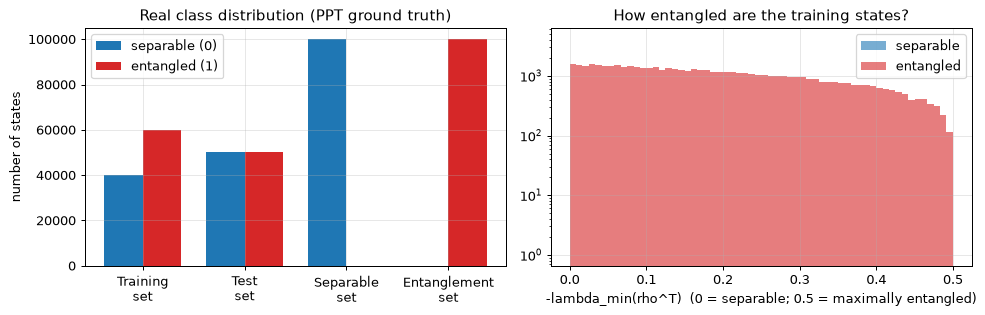

In [6]:
Xtr, ytr = DATA["Training set"]["x"], DATA["Training set"]["y"]
print("Training matrix shape:", Xtr.shape, "(states x Gell-Mann features); test:", DATA["Test set"]["x"].shape)
print("Feature names (15):", FEATURE_NAMES)
print("Original label values: 0 = separable (PPT), 1 = entangled (NPT)")
rows = []
for k, d in DATA.items():
    c = np.bincount(d["y"], minlength=2)
    rows.append({"set": k, "states": len(d["y"]), "separable (0)": c[0], "entangled (1)": c[1], "share entangled": round(c[1] / len(d["y"]), 3)})
display(pd.DataFrame(rows))
print("\nFeature ranges on the training set (Gell-Mann expectation values of pure states lie in [-1, 1]):")
display(pd.DataFrame(Xtr, columns=FEATURE_NAMES).describe().T[["mean", "std", "min", "max"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
names = list(DATA)
w = 0.38
for j, lab, col in [(0, "separable (0)", "tab:blue"), (1, "entangled (1)", "tab:red")]:
    ax[0].bar(np.arange(4) + (j - 0.5) * w, [int((DATA[n]["y"] == j).sum()) for n in names], w, label=lab, color=col)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels([n.replace(" ", "\n") for n in names]); ax[0].set_ylabel("number of states")
ax[0].set_title("Real class distribution (PPT ground truth)"); ax[0].legend()
for j, lab, col in [(0, "separable", "tab:blue"), (1, "entangled", "tab:red")]:
    v = -DATA["Training set"]["lam"][DATA["Training set"]["y"] == j]
    ax[1].hist(np.clip(v, -0.01, 0.5), bins=60, alpha=0.6, label=lab, color=col)
ax[1].set_yscale("log"); ax[1].set_xlabel("-lambda_min(rho^T)  (0 = separable; 0.5 = maximally entangled)")
ax[1].set_title("How entangled are the training states?"); ax[1].legend()
plt.tight_layout(); plt.show()

explained variance ratio of the first 3 components: [0.185 0.102 0.101]


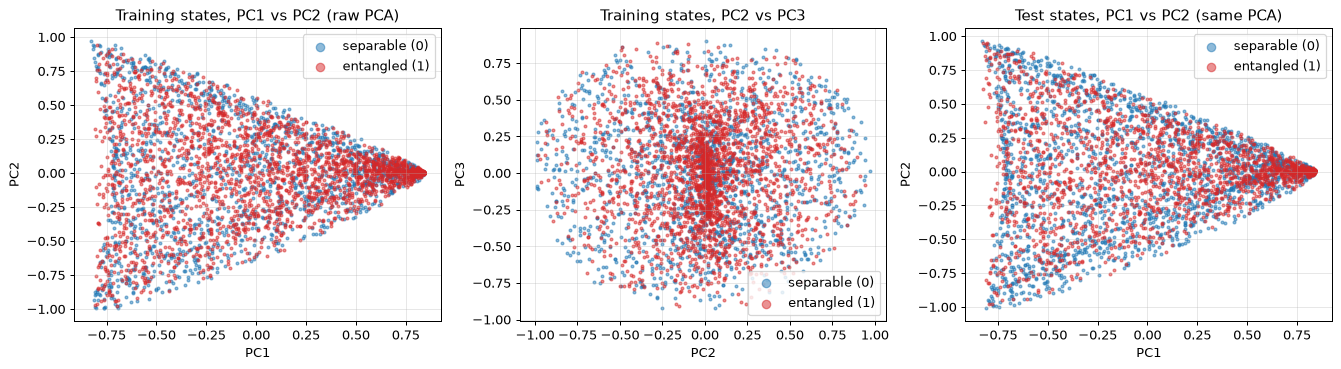

In [7]:
# 2-D scatter of real states coloured by ground-truth label: raw PCA coordinates, PCA fitted on the training split only
pca = PCA(n_components=3, random_state=SEED).fit(Xtr)
print("explained variance ratio of the first 3 components:", pca.explained_variance_ratio_.round(3))
sub = rng_for(101).choice(len(ytr), size=min(4000, len(ytr)), replace=False)
Ztr = pca.transform(Xtr[sub]); ysub = ytr[sub]
Zte_all = pca.transform(DATA["Test set"]["x"]); yte_all = DATA["Test set"]["y"]
subt = rng_for(102).choice(len(yte_all), size=min(4000, len(yte_all)), replace=False)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for j, lab, col in [(0, "separable (0)", "tab:blue"), (1, "entangled (1)", "tab:red")]:
    m = ysub == j
    ax[0].scatter(Ztr[m, 0], Ztr[m, 1], s=5, alpha=0.5, c=col, label=lab)
    ax[1].scatter(Ztr[m, 1], Ztr[m, 2], s=5, alpha=0.5, c=col, label=lab)
    mt = yte_all[subt] == j
    ax[2].scatter(Zte_all[subt][mt, 0], Zte_all[subt][mt, 1], s=5, alpha=0.5, c=col, label=lab)
ax[0].set_title("Training states, PC1 vs PC2 (raw PCA)"); ax[1].set_title("Training states, PC2 vs PC3"); ax[2].set_title("Test states, PC1 vs PC2 (same PCA)")
for a, (xl, yl) in zip(ax, [("PC1", "PC2"), ("PC2", "PC3"), ("PC1", "PC2")]):
    a.set_xlabel(xl); a.set_ylabel(yl); a.legend(markerscale=3)
plt.tight_layout(); plt.show()

**Reading the plots.** Pure product states fill a thin curved manifold inside the cloud of all two-qubit pure states (the separable class has measure zero among pure states), so a linear
projection overlaps the two classes strongly. This is also why the entangled class is hard: weakly entangled states sit right next to the product-state manifold, which is exactly where the paper's
network is least accurate (78 % on entangled states against 100 % on separable states).

## Quantum Circuit Architecture

The classifier is classical, but the **data are quantum states** that a quantum computer would prepare with the circuits below. We draw them with Qiskit and check that the circuits really produce the states
(and the Gell-Mann vectors) used by the notebook. The preparation unitaries are fixed (random) unitaries from the paper's recipe, so these circuits have **no trainable parameters**; the trainable object is the
classical 15-H-1 network in Section 2. The Gell-Mann features are expectation values, which on hardware would be estimated by state tomography (measuring Pauli products), so no explicit measurement gates are drawn.

* *Separable preparation:* two independent single-qubit unitaries `U1 = exp(-i h1 t1)`, `U2 = exp(-i h2 t2)` on `|0>|0>`.
* *Entangled preparation:* one two-qubit unitary `exp(-i t h1 (x) h2)` on `|00>`, compiled by Qiskit into `u` and `cx` gates.

The first drawing of each pair is the circuit built from the paper's unitaries; the second is the **executed**, compiled circuit (basis `u`, `cx`). The equivalence assertions run on random samples of the data generator.

In [8]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Statevector

# Qiskit is little-endian: qubit 1 is the first (most significant) qubit of the paper's |a>|b> ordering, qubit 0 the second.
def circuit_separable(U1, U2):
    qc = QuantumCircuit(2, name="separable state")
    qc.append(UnitaryGate(U1, label="U1=exp(-i h1 t1)"), [1])
    qc.append(UnitaryGate(U2, label="U2=exp(-i h2 t2)"), [0])
    return qc

def circuit_entangled(U):
    qc = QuantumCircuit(2, name="entangling-generator state")
    qc.append(UnitaryGate(U, label="exp(-i t h1(x)h2)"), [0, 1])        # the matrix is ordered (qubit1 (x) qubit0), as in the generator
    return qc

rc = rng_for(103)
psi_s, (U1, U2) = sep_states(rc, 4, return_unitaries=True)
psi_e, (Ue, _, _) = ent_states(rc, 4, return_unitaries=True)
qs = [circuit_separable(U1[i], U2[i]) for i in range(4)]
qe = [circuit_entangled(Ue[i]) for i in range(4)]
BASIS = ["u", "cx"]
ts = [transpile(c, basis_gates=BASIS, optimization_level=1, seed_transpiler=SEED) for c in qs]
te = [transpile(c, basis_gates=BASIS, optimization_level=1, seed_transpiler=SEED) for c in qe]

def overlap(a, b):
    return abs(np.vdot(a, b))
worst = 1.0
for circs, psi in [(qs, psi_s), (ts, psi_s), (qe, psi_e), (te, psi_e)]:
    for c, p in zip(circs, psi):
        worst = min(worst, overlap(Statevector.from_instruction(c).data, p))
assert worst > 1 - 1e-9, worst
# Gell-Mann vectors measured on the executed circuits equal the notebook features
for c, p in zip(te, psi_e):
    sv = Statevector.from_instruction(c).data
    assert np.allclose(gm_features(sv[None]), gm_features(p[None]), atol=1e-9)
print(f"Equivalence check passed: |<circuit|generator state>| >= {worst:.12f} for 16 circuits (up to a global phase); Gell-Mann vectors identical.")

Equivalence check passed: |<circuit|generator state>| >= 1.000000000000 for 16 circuits (up to a global phase); Gell-Mann vectors identical.


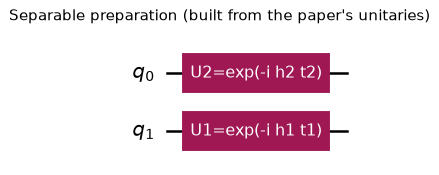

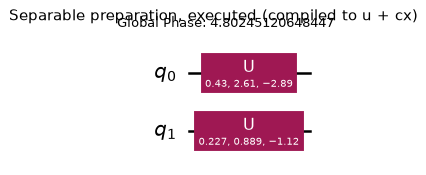

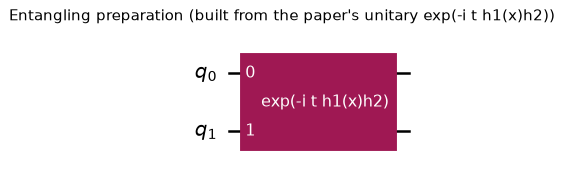

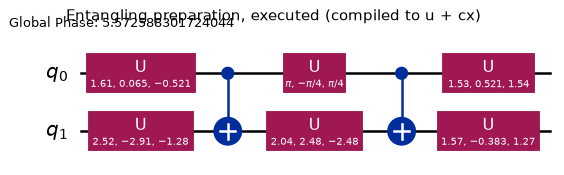

,circuit,qubits,depth,gate counts,trainable parameters,free random-draw parameters
0,separable (paper unitaries),2,1,{'unitary': 2},0,"h1,h2,t (fixed per sample)"
1,separable (executed),2,1,{'u': 2},0,"h1,h2,t (fixed per sample)"
2,entangling (paper unitary),2,1,{'unitary': 1},0,"h1,h2,t (fixed per sample)"
3,entangling (executed),2,5,"{'u': 6, 'cx': 2}",0,"h1,h2,t (fixed per sample)"


Assumptions: the paper does not give the distribution of h1, h2, t (CHOICE above); the 2-qubit unitary is synthesised by Qiskit (KAK) into at most 3 CX gates.


In [9]:
fig = qs[0].draw("mpl", fold=-1); fig.suptitle("Separable preparation (built from the paper's unitaries)"); display(fig)
fig = ts[0].draw("mpl", fold=-1); fig.suptitle("Separable preparation, executed (compiled to u + cx)"); display(fig)
fig = qe[0].draw("mpl", fold=-1); fig.suptitle("Entangling preparation (built from the paper's unitary exp(-i t h1(x)h2))"); display(fig)
fig = te[0].draw("mpl", fold=-1); fig.suptitle("Entangling preparation, executed (compiled to u + cx)"); display(fig)
rows = []
for name, c in [("separable (paper unitaries)", qs[0]), ("separable (executed)", ts[0]), ("entangling (paper unitary)", qe[0]), ("entangling (executed)", te[0])]:
    rows.append({"circuit": name, "qubits": c.num_qubits, "depth": c.depth(), "gate counts": dict(c.count_ops()),
                 "trainable parameters": 0, "free random-draw parameters": "h1,h2,t (fixed per sample)"})
display(pd.DataFrame(rows))
print("Assumptions: the paper does not give the distribution of h1, h2, t (CHOICE above); the 2-qubit unitary is synthesised by Qiskit (KAK) into at most 3 CX gates.")

## 2. The classical classifier (15 - H - 1 network)

The paper's network is `y_hat = sigmoid(w2 . ReLU(W1 x + b1) + b2)` with 15 inputs, one hidden layer and one output (Eqs. 7-9), trained with binary cross-entropy and SGD.
PyTorch and TensorFlow are not needed: the model is small and **both the parameter gradients and the input gradient (needed by FGSM and DeepFool) have a closed form**, so we write
them in numpy and *check them against finite differences*. The paper's hidden layer has 100 000 neurons; we use `HIDDEN` neurons (config cell) to keep the CPU time reasonable.

* Parameter gradients, mini-batch `B`: `g = (p - y)/B`, `dw2 = A^T g`, `dA = g w2^T * 1[A>0]`, `dW1 = X^T dA`.
* Input gradient of the logit `z`: `dz/dx = ((1[pre>0] * w2) @ W1^T)`.

In [10]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -60, 60)))

class MLP:
    """15 -> HIDDEN (ReLU) -> 1 (sigmoid), BCE loss, mini-batch SGD, exact input gradients. float32 by default."""
    def __init__(self, hidden, seed, dtype=np.float32, d_in=15):
        r = np.random.default_rng([SEED, 7, seed])
        k1, k2 = 1 / np.sqrt(d_in), 1 / np.sqrt(hidden)                              # PyTorch-style uniform initialisation
        self.W1 = r.uniform(-k1, k1, (d_in, hidden)).astype(dtype); self.b1 = r.uniform(-k1, k1, hidden).astype(dtype)
        self.w2 = r.uniform(-k2, k2, hidden).astype(dtype); self.b2 = dtype(0)
        self.dtype = dtype; self.seed = seed; self.history = []

    def _pre(self, X):
        return X @ self.W1 + self.b1

    def logit(self, X, chunk=4096):
        X = np.asarray(X, dtype=self.dtype)
        return np.concatenate([np.maximum(self._pre(X[i:i + chunk]), 0) @ self.w2 + self.b2 for i in range(0, len(X), chunk)])

    def logit_and_input_grad(self, X, chunk=2048):
        X = np.asarray(X, dtype=self.dtype); zs, gs = [], []
        for i in range(0, len(X), chunk):
            pre = self._pre(X[i:i + chunk]); m = pre > 0
            zs.append(np.maximum(pre, 0) @ self.w2 + self.b2)
            gs.append((m * self.w2) @ self.W1.T)                                      # d logit / d x
        return np.concatenate(zs), np.concatenate(gs)

    def predict(self, X):
        return (self.logit(X) > 0).astype(int)

    def fit(self, X, y, epochs, lr, batch, verbose=True):
        X = np.asarray(X, dtype=self.dtype); y = np.asarray(y, dtype=self.dtype); n = len(y)
        for ep in range(epochs):
            lr_ep = lr * (1 - 0.9 * ep / max(epochs - 1, 1))                          # CHOICE: linear decay to 10 %
            perm = np.random.default_rng([SEED, 8, self.seed, ep]).permutation(n)
            tl = 0.0; tc = 0
            for i in range(0, n, batch):
                idx = perm[i:i + batch]; xb, yb = X[idx], y[idx]
                pre = self._pre(xb); A = np.maximum(pre, 0); z = A @ self.w2 + self.b2
                p = sigmoid(z).astype(self.dtype)
                tl += float((np.logaddexp(0, z) - yb * z).sum()); tc += int(((z > 0) == (yb > 0.5)).sum())
                g = ((p - yb) / len(yb)).astype(self.dtype)
                dA = np.outer(g, self.w2) * (pre > 0)
                self.W1 -= lr_ep * (xb.T @ dA); self.b1 -= lr_ep * dA.sum(0)
                self.w2 -= lr_ep * (A.T @ g); self.b2 = self.dtype(self.b2 - lr_ep * g.sum())
            self.history.append((ep + 1, tl / n, tc / n))
            if verbose and (ep % 5 == 4 or ep == 0 or ep == epochs - 1):
                print(f"  seed {self.seed} epoch {ep+1:3d}/{epochs}  loss {tl/n:.4f}  running train acc {tc/n:.4f}")
        return self

# ---------- gradient check: analytic input gradient and analytic parameter gradient vs finite differences (float64, small net)
chk = MLP(20, seed=0, dtype=np.float64)
Xc = DATA["Training set"]["x"][:6]; yc = DATA["Training set"]["y"][:6].astype(float)
z0, gz = chk.logit_and_input_grad(Xc)
num = np.zeros_like(gz); h = 1e-6
for j in range(15):
    Xp, Xm = Xc.copy(), Xc.copy(); Xp[:, j] += h; Xm[:, j] -= h
    num[:, j] = (chk.logit(Xp) - chk.logit(Xm)) / (2 * h)
assert np.allclose(gz, num, atol=1e-6), np.abs(gz - num).max()
def bce(m, X, y):
    z = m.logit(X); return float((np.logaddexp(0, z) - y * z).mean())
# one SGD step with a tiny lr must equal minus lr * numerical gradient of the loss w.r.t. W1[0,0]
m1 = MLP(20, seed=1, dtype=np.float64); w_before = m1.W1.copy()
Xb, yb = DATA["Training set"]["x"][:32], DATA["Training set"]["y"][:32].astype(float)
l0 = bce(m1, Xb, yb); m1.W1[0, 0] += 1e-6; l1 = bce(m1, Xb, yb); m1.W1[0, 0] -= 2e-6; l2 = bce(m1, Xb, yb); m1.W1[0, 0] += 1e-6
numgrad = (l1 - l2) / 2e-6
m1.fit(Xb, yb, epochs=1, lr=1e-9, batch=32, verbose=False)
assert np.isclose((w_before[0, 0] - m1.W1[0, 0]) / 1e-9, numgrad, rtol=1e-3, atol=1e-6), ((w_before[0, 0] - m1.W1[0, 0]) / 1e-9, numgrad)
print("Gradient checks passed: input gradient and SGD parameter gradient agree with finite differences.")

Gradient checks passed: input gradient and SGD parameter gradient agree with finite differences.


[   0.2 min] training the main classifier


  seed 42 epoch   1/30  loss 0.6435  running train acc 0.6100


  seed 42 epoch   5/30  loss 0.4931  running train acc 0.8072


  seed 42 epoch  10/30  loss 0.4061  running train acc 0.8444


  seed 42 epoch  15/30  loss 0.3663  running train acc 0.8577


  seed 42 epoch  20/30  loss 0.3441  running train acc 0.8670


  seed 42 epoch  25/30  loss 0.3315  running train acc 0.8712


  seed 42 epoch  30/30  loss 0.3251  running train acc 0.8738
[   2.0 min] training done


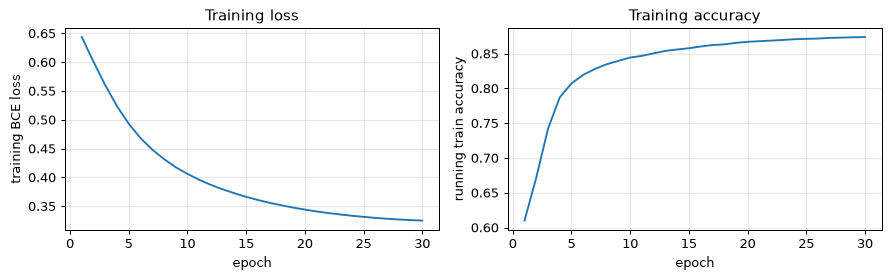

,accuracy (original classifier)
Training set,87.45 %
Test set,88.94 %
Separable set,96.10 %
Entanglement set,81.19 %


In [11]:
def accuracy(model, X, y):
    return float((model.predict(X) == y).mean())

tick("training the main classifier")
MODEL = MLP(HIDDEN, seed=SEED).fit(DATA["Training set"]["x32"], DATA["Training set"]["y"], epochs=EPOCHS, lr=LR, batch=BATCH)
tick("training done")
hist = np.array(MODEL.history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(hist[:, 0], hist[:, 1]); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("training BCE loss"); ax[0].set_title("Training loss")
ax[1].plot(hist[:, 0], hist[:, 2]); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("running train accuracy"); ax[1].set_title("Training accuracy")
plt.tight_layout(); plt.show()

CLEAN = {k: accuracy(MODEL, d["x32"], d["y"]) for k, d in DATA.items()}
display(pd.DataFrame({"accuracy (original classifier)": {k: f"{100*v:.2f} %" for k, v in CLEAN.items()}}))

## 3. Classical baselines on the same inputs

Two other classical models on exactly the same 15-vectors: a random forest and an RBF-SVM (trained on a subset, since the SVM is quadratic in the training size).
The exact PPT test is the oracle (accuracy 100 % by construction; it needs the full density matrix). Later these models also serve as **black-box victims**: are the adversarial vectors crafted on the neural network
also dangerous for them (transferability)?

In [12]:
tick("baselines")
RF = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1).fit(DATA["Training set"]["x"], DATA["Training set"]["y"])
sv_idx = rng_for(104).choice(N_TRAIN, size=min(SVC_TRAIN, N_TRAIN), replace=False)
SVM = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED).fit(DATA["Training set"]["x"][sv_idx], DATA["Training set"]["y"][sv_idx])
ev_idx = {k: rng_for(105, i).choice(len(d["y"]), size=min(EVAL_SUB, len(d["y"])), replace=False) for i, (k, d) in enumerate(DATA.items())}
rows = []
for k, d in DATA.items():
    ii = ev_idx[k]
    rows.append({"set": k, "neural net (full set)": round(100 * CLEAN[k], 2),
                 f"random forest ({len(ii)} rows)": round(100 * float((RF.predict(d["x"][ii]) == d["y"][ii]).mean()), 2),
                 f"RBF-SVM ({len(ii)} rows)": round(100 * float((SVM.predict(d["x"][ii]) == d["y"][ii]).mean()), 2),
                 "PPT oracle": 100.0})
BASE_TABLE = pd.DataFrame(rows).set_index("set")
display(BASE_TABLE)
tick("baselines done")

[   2.2 min] baselines


,neural net (full set),random forest (5000 rows),RBF-SVM (5000 rows),PPT oracle
set,,,,
Training set,87.45,100.00,77.46,100.0
Test set,88.94,94.84,80.60,100.0
Separable set,96.10,99.64,92.98,100.0
Entanglement set,81.19,90.12,68.86,100.0


[   4.8 min] baselines done


## 4. The attacks: FGSM and DeepFool

**FGSM (Eqs. 10-12).** `eta = eps * sign(grad_x L(theta, x, y))`, `x_adv = x + eta`, with the binary cross-entropy `L` of the *true* label. For a sigmoid output
`grad_x L = (p - y) grad_x z`, which we compute exactly.

**DeepFool (Eqs. 13-14).** Treat the logit `z(x)` as the decision function `f`. Repeat `r = -z(x)/||grad z(x)||^2 * grad z(x)` (a step onto the linearised decision boundary), sum the steps, multiply the
total by `(1 + overshoot)` and stop as soon as the *predicted* class differs from the original prediction. DeepFool therefore looks for the **smallest** perturbation, and it also pushes samples the
network already misclassified across the boundary, which makes them "correct" by accident. We therefore also report the fooling rate among initially correct samples.
We add a variant whose total perturbation is clipped to `|r|_inf <= eps`, so that both attacks have the same L-infinity budget.

**Control.** Random sign noise of the same size `eps` (to show that the damage comes from the gradient, not from the size of the perturbation).

In [13]:
def fgsm(model, X, y, eps):
    z, g = model.logit_and_input_grad(X)
    p = sigmoid(z)
    return (np.asarray(X, dtype=np.float32) + eps * np.sign((p - y)[:, None] * g)).astype(np.float32)

def deepfool(model, X, overshoot=DF_OVERSHOOT, max_iter=DF_MAX_ITER, linf=None):
    """Binary DeepFool on the logit. Returns adversarial vectors and the number of iterations used."""
    X = np.asarray(X, dtype=np.float32)
    z0 = model.logit(X); s0 = np.where(z0 >= 0, 1, -1)
    r_tot = np.zeros_like(X); active = np.ones(len(X), bool); iters = np.zeros(len(X), int)
    for it in range(max_iter):
        idx = np.where(active)[0]
        if len(idx) == 0:
            break
        xa = X[idx] + (1 + overshoot) * r_tot[idx]
        if linf is not None:
            xa = X[idx] + np.clip((1 + overshoot) * r_tot[idx], -linf, linf)
        z, g = model.logit_and_input_grad(xa)
        flipped = np.where(z >= 0, 1, -1) != s0[idx]
        active[idx[flipped]] = False
        keep = ~flipped
        if not keep.any():
            break
        j = idx[keep]; gk = g[keep]; zk = z[keep]
        step = -(zk / ((gk ** 2).sum(1) + 1e-12))[:, None] * gk
        r_tot[j] += step.astype(np.float32); iters[j] += 1
        if linf is not None:
            r_tot[j] = np.clip(r_tot[j], -linf, linf)
    pert = (1 + overshoot) * r_tot
    if linf is not None:
        pert = np.clip(pert, -linf, linf)
    return (X + pert).astype(np.float32), iters

def noise_attack(X, eps, seed):
    s = np.random.default_rng([SEED, 9, seed]).choice([-1.0, 1.0], size=np.shape(X))
    return (np.asarray(X, dtype=np.float32) + eps * s).astype(np.float32)

# sanity: with eps = 0 FGSM is the identity and a tiny DeepFool step flips a near-boundary example
d = DATA["Test set"]; assert np.allclose(fgsm(MODEL, d["x32"][:50], d["y"][:50], 0.0), d["x32"][:50])
print("attack helpers ready")

attack helpers ready


In [14]:
tick("attacks at eps = 0.1")
ADV = {}; ROWS = []
for k, d in DATA.items():
    X, y = d["x32"], d["y"]
    xf = fgsm(MODEL, X, y, EPS)
    xd, itd = deepfool(MODEL, X)
    xc, itc = deepfool(MODEL, X, max_iter=DF_CLIP_ITER, linf=EPS)
    xn = noise_attack(X, EPS, 0)
    ADV[k] = dict(fgsm=xf, deepfool=xd, deepfool_clip=xc, noise=xn)
    ok0 = MODEL.predict(X) == y
    acc = lambda Xa: float((MODEL.predict(Xa) == y).mean())
    fool = lambda Xa: float(((MODEL.predict(Xa) != y) & ok0).sum() / max(ok0.sum(), 1))
    ROWS.append({"set": k, "orig": 100 * CLEAN[k], "FGSM": 100 * acc(xf), "DeepFool": 100 * acc(xd), "DeepFool (|r|inf<=eps)": 100 * acc(xc), "random noise": 100 * acc(xn),
                 "FGSM success on initially-correct": 100 * fool(xf), "DeepFool success on initially-correct": 100 * fool(xd),
                 "DeepFool mean |r|_2": float(np.linalg.norm(xd - X, axis=1).mean()), "DeepFool mean |r|_inf": float(np.abs(xd - X).max(1).mean()),
                 "DeepFool mean iters": float(itd.mean())})
ATT = pd.DataFrame(ROWS).set_index("set")
display(ATT.round(2))
tick("attacks done")

[   4.8 min] attacks at eps = 0.1


,orig,FGSM,DeepFool,DeepFool (|r|inf<=eps),random noise,FGSM success on initially-correct,DeepFool success on initially-correct,DeepFool mean |r|_2,DeepFool mean |r|_inf,DeepFool mean iters
set,,,,,,,,,,
Training set,87.46,16.19,12.55,37.44,71.10,81.49,100.0,0.15,0.09,1.04
Test set,88.94,13.57,11.06,31.71,67.99,84.74,100.0,0.13,0.08,1.03
Separable set,96.10,0.00,3.90,3.90,52.19,100.00,100.0,0.05,0.03,1.01
Entanglement set,81.19,26.96,18.81,60.06,83.35,66.80,100.0,0.21,0.12,1.05


[   8.1 min] attacks done


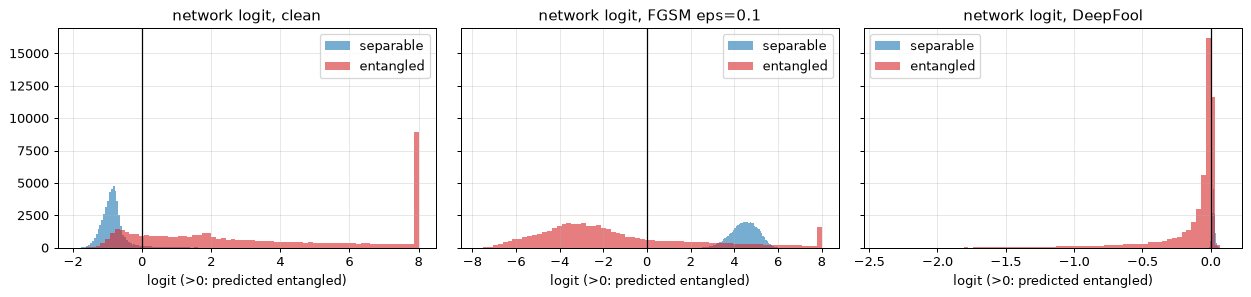

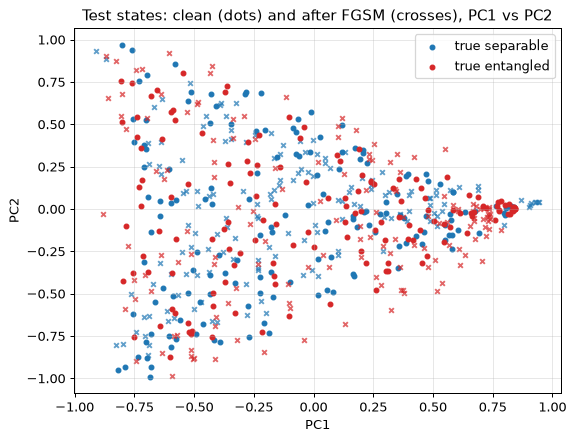

In [15]:
# Where does the logit go? Clean vs FGSM vs DeepFool on the test set, split by true class.
d = DATA["Test set"]; z_clean = MODEL.logit(d["x32"]); z_f = MODEL.logit(ADV["Test set"]["fgsm"]); z_d = MODEL.logit(ADV["Test set"]["deepfool"])
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for a, z, t in zip(ax, [z_clean, z_f, z_d], ["clean", f"FGSM eps={EPS}", "DeepFool"]):
    for j, lab, col in [(0, "separable", "tab:blue"), (1, "entangled", "tab:red")]:
        a.hist(np.clip(z[d["y"] == j], -8, 8), bins=70, alpha=0.6, label=lab, color=col)
    a.axvline(0, color="k", lw=1); a.set_title(f"network logit, {t}"); a.set_xlabel("logit (>0: predicted entangled)"); a.legend()
plt.tight_layout(); plt.show()

# the attack in the PCA plane of Section "Dataset Exploration": a few test states before and after FGSM
ii = rng_for(106).choice(len(d["y"]), size=300, replace=False)
P0 = pca.transform(d["x"][ii]); P1 = pca.transform(ADV["Test set"]["fgsm"][ii].astype(float))
fig, ax = plt.subplots(figsize=(6.5, 5))
for j, col in [(0, "tab:blue"), (1, "tab:red")]:
    m = d["y"][ii] == j
    ax.scatter(P0[m, 0], P0[m, 1], s=14, c=col, label=f"true {'entangled' if j else 'separable'}")
    ax.scatter(P1[m, 0], P1[m, 1], s=14, c=col, marker="x", alpha=0.7)
ax.set_title("Test states: clean (dots) and after FGSM (crosses), PC1 vs PC2"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
plt.tight_layout(); plt.show()

### 4.1 Attack success against perturbation strength (not in the paper)

How small can the perturbation be? We sweep `eps` for FGSM, the clipped DeepFool and the random-noise control on a subset of the test set, and report the *success rate* (share of initially correctly classified states that become misclassified).

[   8.3 min] epsilon sweep


,FGSM,FGSM (separable states),FGSM (entangled states),DeepFool |r|inf<=eps,random noise
eps,,,,,
0.00,0.0,0.0,0.0,0.0,0.0
0.01,7.6,5.9,9.6,3.8,1.0
0.02,49.0,75.8,17.4,13.1,2.8
0.05,73.8,100.0,42.9,64.3,16.4
0.10,84.7,100.0,66.7,76.8,29.5
0.15,91.2,100.0,80.8,83.8,35.7
0.20,95.6,100.0,90.3,89.0,39.8
0.30,98.2,100.0,96.1,96.2,44.6


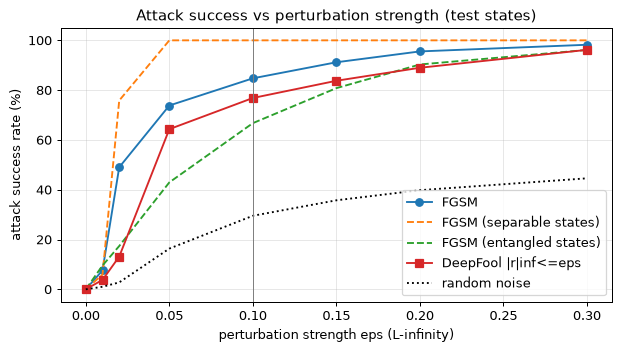

[   9.8 min] sweep done


In [16]:
tick("epsilon sweep")
sw = rng_for(107).choice(N_TEST, size=min(SWEEP_N, N_TEST), replace=False)
Xs, ys = DATA["Test set"]["x32"][sw], DATA["Test set"]["y"][sw]; ok0 = MODEL.predict(Xs) == ys
def success(Xa, mask=None):
    m = ok0 if mask is None else (ok0 & mask)
    wrong = (MODEL.predict(Xa) != ys) & m
    return 100 * float(wrong.sum() / max(m.sum(), 1))
rows = []
for e in EPS_GRID:
    xf = fgsm(MODEL, Xs, ys, e); xc, _ = deepfool(MODEL, Xs, max_iter=DF_CLIP_ITER, linf=e) if e > 0 else (Xs, None); xn = noise_attack(Xs, e, 1)
    rows.append({"eps": e, "FGSM": success(xf), "FGSM (separable states)": success(xf, ys == 0), "FGSM (entangled states)": success(xf, ys == 1),
                 "DeepFool |r|inf<=eps": success(xc), "random noise": success(xn)})
SWEEP = pd.DataFrame(rows).set_index("eps")
display(SWEEP.round(1))
fig, ax = plt.subplots(figsize=(7, 4))
for c, st in [("FGSM", "-o"), ("FGSM (separable states)", "--"), ("FGSM (entangled states)", "--"), ("DeepFool |r|inf<=eps", "-s"), ("random noise", ":k")]:
    ax.plot(SWEEP.index, SWEEP[c], st, label=c)
ax.axvline(EPS, color="gray", lw=0.8); ax.set_xlabel("perturbation strength eps (L-infinity)"); ax.set_ylabel("attack success rate (%)")
ax.set_title("Attack success vs perturbation strength (test states)"); ax.legend(); plt.tight_layout(); plt.show()
tick("sweep done")

### 4.2 Transfer to the random forest and the SVM (not in the paper)

The vectors crafted against the neural network (white-box) are fed to the other two classifiers, which the attacker never queried (black-box transfer). The random-noise column is the control.
Accuracy on `EVAL_SUB` rows of each set.

In [17]:
rows = []
for k, d in DATA.items():
    ii = ev_idx[k]; y = d["y"][ii]; r = {"set": k}
    for nm, key in [("clean", None), ("FGSM", "fgsm"), ("DeepFool", "deepfool"), ("noise", "noise")]:
        Xa = d["x"][ii] if key is None else ADV[k][key][ii].astype(float)
        r[f"RF {nm}"] = round(100 * float((RF.predict(Xa) == y).mean()), 1)
        r[f"SVM {nm}"] = round(100 * float((SVM.predict(Xa) == y).mean()), 1)
    rows.append(r)
TRANSFER = pd.DataFrame(rows).set_index("set")
display(TRANSFER)

,RF clean,SVM clean,RF FGSM,SVM FGSM,RF DeepFool,SVM DeepFool,RF noise,SVM noise
set,,,,,,,,
Training set,100.0,77.5,56.6,13.3,79.9,47.6,61.3,74.7
Test set,94.8,80.6,47.3,12.1,73.3,54.6,51.6,74.9
Separable set,99.6,93.0,0.0,0.0,54.9,89.8,4.0,77.9
Entanglement set,90.1,68.9,94.9,23.2,92.9,19.6,99.2,73.6


### 4.3 Repeating with other training seeds

Table 1 for two further random initialisations / batch orders of the network (same data). Headline numbers in Section 6 are the main-seed values and the mean +- std over the three runs.

In [18]:
tick("extra seeds")
print(f"All three seeds are evaluated on the first {min(SEED_SUB, N_TEST)} rows of every set (the sets are already shuffled), so the rows are comparable.")
SEED_ROWS = []
for s in range(0, N_EXTRA_SEEDS + 1):
    m = MODEL if s == 0 else MLP(HIDDEN, seed=SEED + s).fit(DATA["Training set"]["x32"], DATA["Training set"]["y"], epochs=EPOCHS, lr=LR, batch=BATCH, verbose=False)
    row = {"seed": SEED + s}
    for k, d in DATA.items():
        X, y = d["x32"][:SEED_SUB], d["y"][:SEED_SUB]
        row[f"{k}|orig"] = 100 * float((m.predict(X) == y).mean())
        row[f"{k}|FGSM"] = 100 * float((m.predict(fgsm(m, X, y, EPS)) == y).mean())
        row[f"{k}|DeepFool"] = 100 * float((m.predict(deepfool(m, X)[0]) == y).mean())
    SEED_ROWS.append(row); tick(f"seed {SEED + s} done")
SEEDS = pd.DataFrame(SEED_ROWS).set_index("seed")
SEED_MEAN, SEED_STD = SEEDS.mean(), SEEDS.std(ddof=0)
tab = pd.DataFrame({k: {c: f"{SEED_MEAN[f'{k}|{c}']:.2f} +- {SEED_STD[f'{k}|{c}']:.2f}" for c in ["orig", "FGSM", "DeepFool"]} for k in DATA}).T
tab.columns = ["original (mean +- std)", "FGSM (mean +- std)", "DeepFool (mean +- std)"]
display(tab)

[  11.2 min] extra seeds
All three seeds are evaluated on the first 20000 rows of every set (the sets are already shuffled), so the rows are comparable.


[  11.6 min] seed 42 done


[  14.9 min] seed 43 done


[  18.0 min] seed 44 done


,original (mean +- std),FGSM (mean +- std),DeepFool (mean +- std)
Training set,87.63 +- 0.19,15.93 +- 0.10,12.37 +- 0.19
Test set,88.67 +- 0.06,13.61 +- 0.06,11.33 +- 0.06
Separable set,96.27 +- 0.14,0.00 +- 0.00,3.73 +- 0.14
Entanglement set,81.08 +- 0.28,26.79 +- 0.07,18.93 +- 0.28


## 5. Back to quantum states: distance, fidelity and physicality (Tables 2 and 3)

The paper rebuilds a density operator from every adversarial vector, `rho_adv = (sum_k x_adv,k M_k + I)/Z` with `Z = Tr(...)`, and compares it with the original state.

**An important observation.** Because `Tr(M_k) = 0`, `Z` is always 4, so this formula gives `rho_adv = I/4 + (1/4) sum x M`. But the true state is `rho = I/4 + (1/2) sum x M` (the factor `1/2` comes from `Tr(M_i M_j) = 2`).
The paper's reconstruction therefore **shrinks the Bloch-like part by a factor 2 even for the unperturbed vector**: for a pure state it gives `rho/2 + I/8`, with trace distance exactly 3/8 = 0.375 and squared fidelity 5/8 = 0.625 (root fidelity 0.79)
from the original, with no attack at all. We check this numerically below. The smallest distance in the paper's tables is 0.3750 and its largest fidelity 0.7906 = sqrt(5/8), so this normalisation is what the paper used,
and it explains the large "distances" (0.47) for a perturbation of only `eps = 0.1`. We therefore report two reconstructions:

* **paper**: the formula above (to compare with Tables 2 and 3);
* **exact**: `rho_adv = I/4 + (1/2) sum x_adv M`, the true inverse (this one can be non-positive, i.e. not a state).

Distance = trace distance `D = (1/2)||rho - sigma||_1`; fidelity: squared `F = Tr(rho sigma)` (exact for a pure `rho`) and root fidelity `sqrt(F)`.

In [19]:
def recon_paper(x):
    S = np.einsum("nk,kab->nab", x.astype(float), GM) + np.eye(4)
    return S / np.trace(S, axis1=1, axis2=2).real[:, None, None]                    # Z = Tr(sum x M + I)
def recon_exact(x):
    return np.eye(4) / 4 + 0.5 * np.einsum("nk,kab->nab", x.astype(float), GM)
def trace_distance(r, s):
    return 0.5 * np.abs(np.linalg.eigvalsh((r - s + (r - s).conj().transpose(0, 2, 1)) / 2)).sum(1)
def fid_sq(r, s):                                   # Tr(rho sigma): equals the Uhlmann fidelity when rho is pure
    return np.clip(np.einsum("nij,nji->n", r, s).real, 0, 1)

# check 1: the original vector is reconstructed exactly by the exact formula, and the paper formula gives distance 0.375, F = 0.625
d = DATA["Test set"]; rho0 = density(d["psi"])
assert np.allclose(recon_exact(d["x"]), rho0)
dd0 = trace_distance(rho0, recon_paper(d["x"])); ff0 = fid_sq(rho0, recon_paper(d["x"]))
assert np.allclose(dd0, 0.375) and np.allclose(ff0, 0.625)
print(f"No attack, paper reconstruction: trace distance {dd0.mean():.4f}, F {ff0.mean():.4f}, sqrt(F) {np.sqrt(ff0).mean():.4f}  (paper's smallest distance 0.3750, largest fidelity 0.7906)")

No attack, paper reconstruction: trace distance 0.3750, F 0.6250, sqrt(F) 0.7906  (paper's smallest distance 0.3750, largest fidelity 0.7906)


In [20]:
tick("quantum analysis")
def stats(v):
    return dict(min=float(v.min()), max=float(v.max()), mean=float(v.mean()))
QA = {}
for att in ["fgsm", "deepfool"]:
    for k, d in DATA.items():
        rho0 = density(d["psi"]); xa = ADV[k][att]
        sp, se = recon_paper(xa), recon_exact(xa)
        lam_p = np.linalg.eigvalsh(sp)[:, 0]; lam_e = np.linalg.eigvalsh(se)[:, 0]
        Dp, Fp = trace_distance(rho0, sp), fid_sq(rho0, sp)
        De, Fe = trace_distance(rho0, se), fid_sq(rho0, se)
        phys = lam_e > 0
        # physical entanglement class of the exactly reconstructed adversarial state (PPT test) vs. the network's verdict on it
        ppt_adv = (ppt_min_eig(se[phys]) < -PPT_TOL).astype(int) if phys.any() else np.array([], int)
        pred = MODEL.predict(xa)[phys]; y0 = d["y"][phys]
        QA[(att, k)] = dict(D_paper=stats(Dp), F_paper=stats(Fp), rootF_paper=stats(np.sqrt(Fp)), D_exact=stats(De), F_exact=stats(Fe),
                            phys_paper=100 * float((lam_p > 0).mean()), phys_exact=100 * float(phys.mean()),
                            true_label_flipped=100 * float((ppt_adv != y0).mean()) if phys.any() else float("nan"),
                            net_wrong_vs_true_adv=100 * float((pred != ppt_adv).mean()) if phys.any() else float("nan"),
                            net_wrong_vs_orig=100 * float((MODEL.predict(xa)[phys] != y0).mean()) if phys.any() else float("nan"))
rows = []
for (att, k), q in QA.items():
    rows.append({"attack": att, "set": k, "D paper: min": q["D_paper"]["min"], "max": q["D_paper"]["max"], "mean": q["D_paper"]["mean"],
                 "sqrtF paper: min": q["rootF_paper"]["min"], "max ": q["rootF_paper"]["max"], "mean ": q["rootF_paper"]["mean"],
                 "F (squared) mean": q["F_paper"]["mean"], "physical % (paper rec.)": q["phys_paper"]})
QA_TABLE = pd.DataFrame(rows).set_index(["attack", "set"])
display(QA_TABLE.round(4))
tick("quantum analysis done")

[  18.1 min] quantum analysis


D paper: min     max    mean  sqrtF paper: min  \
attack   set                                                                
fgsm     Training set            0.3040  0.4799  0.3937            0.7220   
         Test set                0.3070  0.4809  0.3945            0.7209   
         Separable set           0.3287  0.4499  0.3992            0.7424   
         Entanglement set        0.3058  0.4811  0.3899            0.7206   
deepfool Training set            0.3697  0.7422  0.3906            0.5149   
         Test set                0.3700  0.7368  0.3885            0.5166   
         Separable set           0.3712  0.3814  0.3772            0.7865   
         Entanglement set        0.3696  0.7454  0.3994            0.5124   

                             max    mean   F (squared) mean  \
attack   set                                                  
fgsm     Training set      0.8363  0.7832            0.6138   
         Test set          0.8363  0.7824            0.6124   
         Separable set     0.8214  0.7774            0.6047   
         Entanglement set  0.8354  0.7872            0.6199   
deepfool Training set      0.7941  0.7826            0.6131   
         Test set          0.7939  0.7836            0.6145   
         Separable set     0.7930  0.7891            0.6228   
         Entanglement set  0.7941  0.7783            0.6066   

                           physical % (paper rec.)  
attack   set                                        
fgsm     Training set                        100.0  
         Test set                            100.0  
         Separable set                       100.0  
         Entanglement set                    100.0  
deepfool Training set                        100.0  
         Test set                            100.0  
         Separable set                       100.0  
         Entanglement set                    100.0

[  19.9 min] quantum analysis done


D exact: mean  F exact: mean  \
attack   set                                              
fgsm     Training set              0.228          0.964   
         Test set                  0.228          0.962   
         Separable set             0.227          0.953   
         Entanglement set          0.228          0.971   
deepfool Training set              0.087          0.975   
         Test set                  0.078          0.978   
         Separable set             0.028          0.995   
         Entanglement set          0.126          0.962   

                           physical % (exact inverse)  \
attack   set                                            
fgsm     Training set                           0.000   
         Test set                               0.000   
         Separable set                          0.000   
         Entanglement set                       0.000   
deepfool Training set                           0.123   
         Test set                               0.101   
         Separable set                          0.000   
         Entanglement set                       0.200   

                           of those: true entanglement class changed %  \
attack   set                                                             
fgsm     Training set                                              NaN   
         Test set                                                  NaN   
         Separable set                                             NaN   
         Entanglement set                                          NaN   
deepfool Training set                                           81.301   
         Test set                                               83.168   
         Separable set                                             NaN   
         Entanglement set                                       83.000   

                           network wrong vs ORIGINAL label %  \
attack   set                                                   
fgsm     Training set                                    NaN   
         Test set                                        NaN   
         Separable set                                   NaN   
         Entanglement set                                NaN   
deepfool Training set                                  100.0   
         Test set                                      100.0   
         Separable set                                   NaN   
         Entanglement set                              100.0   

                           network wrong vs TRUE class of the adversarial state %  
attack   set                                                                       
fgsm     Training set                                                    NaN       
         Test set                                                        NaN       
         Separable set                                                   NaN       
         Entanglement set                                                NaN       
deepfool Training set                                                 18.699       
         Test set                                                     16.832       
         Separable set                                                   NaN       
         Entanglement set                                             17.000

Reading: with the exact inverse an adversarial vector is a legitimate state only if its density matrix is positive semidefinite. For those states the PPT test gives the *true* class of the adversarial state;
'network wrong vs TRUE class' is the share of genuine network errors, while 'true class changed' is the share where the attack simply moved the state across the physical entanglement boundary.


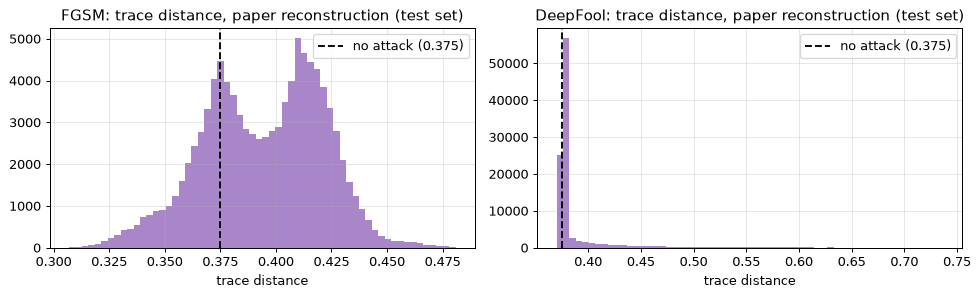

In [21]:
rows = []
for (att, k), q in QA.items():
    rows.append({"attack": att, "set": k, "D exact: mean": q["D_exact"]["mean"], "F exact: mean": q["F_exact"]["mean"], "physical % (exact inverse)": q["phys_exact"],
                 "of those: true entanglement class changed %": q["true_label_flipped"], "network wrong vs ORIGINAL label %": q["net_wrong_vs_orig"],
                 "network wrong vs TRUE class of the adversarial state %": q["net_wrong_vs_true_adv"]})
QA_EXACT = pd.DataFrame(rows).set_index(["attack", "set"])
display(QA_EXACT.round(3))
print("Reading: with the exact inverse an adversarial vector is a legitimate state only if its density matrix is positive semidefinite. For those states the PPT test gives the *true* class of the adversarial state;")
print("'network wrong vs TRUE class' is the share of genuine network errors, while 'true class changed' is the share where the attack simply moved the state across the physical entanglement boundary.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, att, t in zip(ax, ["fgsm", "deepfool"], ["FGSM", "DeepFool"]):
    d = DATA["Test set"]; sp = recon_paper(ADV["Test set"][att])
    a.hist(trace_distance(density(d["psi"]), sp), bins=60, color="tab:purple", alpha=0.8)
    a.axvline(0.375, color="k", ls="--", label="no attack (0.375)"); a.set_title(f"{t}: trace distance, paper reconstruction (test set)"); a.set_xlabel("trace distance"); a.legend()
plt.tight_layout(); plt.show()

## 6. Side by side with the paper

Verdict rule: an accuracy within 2 points of the paper's is *reproduced*; a distance or fidelity within 0.02 is *reproduced*; otherwise *not reached* (we are weaker) or *exceeded* (we are stronger) with the gap. Accuracy after an attack: lower means a stronger attack.
Our numbers are the main-seed run; the mean +- std over seeds is in Section 4.3.

In [22]:
PAPER_T1 = {"Training set": (87.24, 16.72, 17.61), "Test set": (89.06, 14.05, 15.87), "Separable set": (100.0, 0.0, 4.17), "Entanglement set": (78.43, 27.81, 27.26)}
PAPER_T2 = {"fgsm": {"Training set": (0.4737, 0.7294), "Test set": (0.4739, 0.7293), "Separable set": (0.4417, 0.7496), "Entanglement set": (0.4736, 0.7295)},
            "deepfool": {"Training set": (0.4696, 0.7311), "Test set": (0.4700, 0.7308), "Separable set": (0.4472, 0.7445), "Entanglement set": (0.4698, 0.7310)}}

def verdict(paper, ours, tol, lower_is_stronger=False):
    gap = ours - paper
    if abs(gap) <= tol:
        return "reproduced"
    if lower_is_stronger:
        return f"exceeded by {abs(gap):.2f}" if gap < 0 else f"not reached (gap {gap:.2f})"
    return f"{'exceeded' if gap > 0 else 'not reached'} (gap {gap:+.2f})"

rows = []
for k, (a0, af, ad) in PAPER_T1.items():
    rows.append({"claim": f"Table 1 accuracy, original classifier, {k}", "paper": a0, "ours": 100 * CLEAN[k], "verdict": verdict(a0, 100 * CLEAN[k], 2.0)})
    rows.append({"claim": f"Table 1 accuracy after FGSM, {k}", "paper": af, "ours": ATT.loc[k, "FGSM"], "verdict": verdict(af, ATT.loc[k, "FGSM"], 2.0, True)})
    rows.append({"claim": f"Table 1 accuracy after DeepFool, {k}", "paper": ad, "ours": ATT.loc[k, "DeepFool"], "verdict": verdict(ad, ATT.loc[k, "DeepFool"], 2.0, True)})
for att, name in [("fgsm", "Table 2 (FGSM)"), ("deepfool", "Table 3 (DeepFool)")]:
    for k, (pd_, pf) in PAPER_T2[att].items():
        q = QA[(att, k)]
        rows.append({"claim": f"{name} average trace distance, {k}", "paper": pd_, "ours": q["D_paper"]["mean"], "verdict": verdict(pd_, q["D_paper"]["mean"], 0.02)})
        rows.append({"claim": f"{name} average fidelity (root), {k}", "paper": pf, "ours": q["rootF_paper"]["mean"], "verdict": verdict(pf, q["rootF_paper"]["mean"], 0.02)})
CMP = pd.DataFrame(rows)
display(CMP.round(4))

# qualitative claims
t = DATA["Test set"]
drop_f = 100 * CLEAN["Test set"] - ATT.loc["Test set", "FGSM"]; drop_d = 100 * CLEAN["Test set"] - ATT.loc["Test set", "DeepFool"]
sep_vs_ent = ATT.loc["Separable set", "FGSM"] < ATT.loc["Entanglement set", "FGSM"]
phys_all = all(QA[(a, k)]["phys_paper"] > 99.99 for a in ["fgsm", "deepfool"] for k in DATA)
sep_gt_ent = CLEAN["Separable set"] > CLEAN["Entanglement set"]
qual = pd.DataFrame([
    {"claim": "(1) both attacks fool the classifier (test accuracy falls by > 50 points)", "paper": "89.06 -> 14.05 / 15.87", "ours": f"{100*CLEAN['Test set']:.1f} -> {ATT.loc['Test set','FGSM']:.1f} / {ATT.loc['Test set','DeepFool']:.1f}",
     "verdict": "reproduced" if drop_f > 50 and drop_d > 50 else "not reached"},
    {"claim": "(2) separable states are easier to turn entangled than the reverse (FGSM accuracy: separable < entangled set)", "paper": "0 % < 27.81 %", "ours": f"{ATT.loc['Separable set','FGSM']:.1f} % vs {ATT.loc['Entanglement set','FGSM']:.1f} %",
     "verdict": "reproduced" if sep_vs_ent else "not reached"},
    {"claim": "(3) classifier finds entangled states harder than separable ones (original accuracy)", "paper": "100 % vs 78.43 %", "ours": f"{100*CLEAN['Separable set']:.1f} % vs {100*CLEAN['Entanglement set']:.1f} %",
     "verdict": "reproduced" if sep_gt_ent else "not reached"},
    {"claim": "(4) all adversarial samples are real physical states (paper's reconstruction, lambda_min > 0)", "paper": "all", "ours": f"{min(QA[(a,k)]['phys_paper'] for a in ['fgsm','deepfool'] for k in DATA):.2f} % at worst",
     "verdict": "reproduced" if phys_all else "not reached"},
    {"claim": "(5) adversarial states keep high fidelity ('method works')", "paper": "sqrt-F about 0.73", "ours": "see the warning in Section 5: 0.79 even with no attack under the paper's normalisation", "verdict": "cannot be checked as a statement about the attack (the normalisation dominates the number)"},
])
pd.set_option("display.max_colwidth", 140)
display(qual)
ok = (CMP["verdict"] == "reproduced").sum()
print(f"{ok} of {len(CMP)} numeric entries within tolerance of the paper.")

,claim,paper,ours,verdict
0,"Table 1 accuracy, original classifier, Trainin...",87.2400,87.4550,reproduced
1,"Table 1 accuracy after FGSM, Training set",16.7200,16.1890,reproduced
2,"Table 1 accuracy after DeepFool, Training set",17.6100,12.5470,exceeded by 5.06
3,"Table 1 accuracy, original classifier, Test set",89.0600,88.9430,reproduced
4,"Table 1 accuracy after FGSM, Test set",14.0500,13.5740,reproduced
5,"Table 1 accuracy after DeepFool, Test set",15.8700,11.0570,exceeded by 4.81
6,"Table 1 accuracy, original classifier, Separab...",100.0000,96.1010,not reached (gap -3.90)
7,"Table 1 accuracy after FGSM, Separable set",0.0000,0.0000,reproduced
8,"Table 1 accuracy after DeepFool, Separable set",4.1700,3.8990,reproduced
9,"Table 1 accuracy, original classifier, Entangl...",78.4300,81.1870,exceeded (gap +2.76)


,claim,paper,ours,verdict
0,(1) both attacks fool the classifier (test accuracy falls by > 50 points),89.06 -> 14.05 / 15.87,88.9 -> 13.6 / 11.1,reproduced
1,(2) separable states are easier to turn entangled than the reverse (FGSM accuracy: separable < entangled set),0 % < 27.81 %,0.0 % vs 27.0 %,reproduced
2,(3) classifier finds entangled states harder than separable ones (original accuracy),100 % vs 78.43 %,96.1 % vs 81.2 %,reproduced
3,"(4) all adversarial samples are real physical states (paper's reconstruction, lambda_min > 0)",all,100.00 % at worst,reproduced
4,(5) adversarial states keep high fidelity ('method works'),sqrt-F about 0.73,see the warning in Section 5: 0.79 even with no attack under the paper's normalisation,cannot be checked as a statement about the attack (the normalisation dominates the number)


7 of 28 numeric entries within tolerance of the paper.


## 7. Reading the paper critically

* **The data recipe is under-specified.** The distribution of `h1`, `h2`, `t` is not given; it controls how many entangled states are only weakly entangled, and therefore the entangled-class accuracy (78 % in the paper). Our numbers depend on `T_MAX` and on the Gaussian ensemble.
* **The tables mostly measure a normalisation choice.** The reconstruction `(sum x M + I)/Tr(...)` is not the inverse of the Gell-Mann map (a factor 2 is missing), so the "distance 0.47, fidelity 0.73" of Tables 2 and 3 is mostly the 0.375 / 0.79 you get with *no* perturbation at all. They say little about how close the adversarial states are to the originals (the exact reconstruction is in Section 5).
* **"All adversarial samples are real physical states" is a property of the shrunken reconstruction** (a state mixed with `I/8` stays positive), not of the attack. Pure states lie on the *boundary* of the set of density matrices (one eigenvalue is exactly 0), so with the exact inverse almost any perturbation leaves the set: the table in Section 5 shows that practically none of the adversarial vectors is a legitimate state, and the PPT test cannot even be applied to them. The few that are legitimate (DeepFool, tiny steps) show that the attack can change the true entanglement class of a physical state.
* **Our distances are smaller than the paper's.** Under the paper's reconstruction we obtain mean trace distances of about 0.39 and root fidelities of about 0.78, against 0.47 and 0.73 in the paper, although the zero-perturbation floor (0.375 / 0.79) agrees exactly. The paper's perturbations must therefore have been larger than an L-infinity `eps = 0.1` on our features, or its features were scaled differently; the paper does not allow us to decide. We report this as "not reached / exceeded" and do not tune anything to close the gap.
* **Accuracy after DeepFool is largely the initial error rate.** DeepFool pushes every sample across the decision boundary, including those already misclassified, which then count as "correct". The right quantity is the fooling rate among initially correct samples.
* **FGSM and DeepFool here attack a classical network on a classical vector.** Nothing quantum is attacked: the "quantum" part is only the data source. An attacker with access to the 15 numbers is an attacker of the tomography output, not of a quantum device. The attacks also act on features which are not independent (they must come from a density matrix), which is why many perturbed vectors are unphysical.
* **Perturbation strength.** `eps = 0.1` is 10 % of the full range [-1, 1] of each Gell-Mann coordinate; compared with the random-noise control (Section 4.1) the loss of accuracy is clearly caused by the gradient direction, but for a classifier that is only about 80 % accurate, many states sit close to the boundary anyway.
* **A 100 000-neuron layer is not necessary** for this 15-dimensional task; the width only changes the optimisation regime. Our narrower network behaves qualitatively the same, but the exact percentages are not expected to match.
* **What this run shows (FAST_MODE = False, main seed).** Test accuracy of the classifier 88.9 % (paper 89.06 %); FGSM at eps = 0.1 drops it to 13.6 % (paper 14.05 %), the separable set to 0 % (paper 0 %) and the entangled set to 27.0 % (paper 27.81 %): the qualitative story of Table 1 and the FGSM column are reproduced, partly to within the 2-point tolerance. DeepFool leaves 11.1 % on the test set (paper 15.87 %), which is simply the share the network already got wrong, and the separable-set accuracy before the attack (96.1 %) stays below the paper's 100 %. The random-noise control keeps 68 % accuracy against 14 % for FGSM at the same budget, so the damage comes from the gradient direction. Random forest and SVM trained on the same inputs are also fooled by the transferred FGSM vectors (RF 47 %, SVM 12 % on the test set). Wall-clock time of the committed full run: about 20 minutes on an idle laptop CPU with one BLAS thread (an earlier identical run on a heavily shared CPU took 61 minutes); hidden width 2 000 instead of 100 000.

## 8. Exercises

1. Change `T_MAX` (e.g. 0.3, 1, 2 pi) and re-run: how do the entangled-class accuracy and the attack success rate change? Explain with the histogram of `-lambda_min`.
2. Replace the paper's reconstruction by the exact one in the physicality test. What share of FGSM vectors are legitimate states? Can you add a projection onto the set of density matrices (clip negative eigenvalues) and re-measure the attack success?
3. Add an L2 version of FGSM (`eta = eps g/||g||`) and compare its success to the L-infinity version at equal L2 norm.
4. Adversarial training: add FGSM examples (with the true PPT label of the exactly reconstructed physical states) to the training set and measure the new accuracy under attack.
5. Use the exact PPT oracle on the adversarial states to build a "physics-aware" attack that must keep the true class unchanged (so the network is genuinely wrong, not the label). How much larger must `eps` be?